The datatab.net "Retail" example loads its data client-side via JavaScript, so it
could not be scraped directly. This notebook instead uses a representative synthetic
dataset generated for the same scenario: predicting which product category a customer
is most likely to buy from Age, Annual Income, Time on Site and Loyalty Membership.
This is a multi-class classification problem (Electronics / Clothing / Groceries).

In [1]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn import metrics
import seaborn as sn

In [2]:
rng = np.random.default_rng(7)
n = 240
products = ['Electronics', 'Clothing', 'Groceries']

age = rng.integers(18, 70, n)
income = rng.normal(55000, 18000, n).round(0)
time_on_site = rng.normal(12, 5, n).clip(1).round(1)
loyalty_member = rng.integers(0, 2, n)

score_electronics = 0.0002 * income + 0.4 * time_on_site - 0.08 * age + rng.normal(0, 1, n)
score_clothing = 0.12 * age + 0.5 * time_on_site + 1.5 * loyalty_member + rng.normal(0, 1, n)
score_groceries = 0.2 * age + 0.00006 * income + rng.normal(0, 1, n)

scores = np.vstack([score_electronics, score_clothing, score_groceries]).T
product = np.array(products)[scores.argmax(axis=1)]

data = pd.DataFrame({
    'Age': age,
    'AnnualIncome': income,
    'TimeOnSiteMinutes': time_on_site,
    'LoyaltyMember': loyalty_member,
    'Product': product,
})
data.to_csv('retail.csv', index=False)
data.head()

,Age,AnnualIncome,TimeOnSiteMinutes,LoyaltyMember,Product
0,67,58469.0,11.6,1,Groceries
1,50,56608.0,14.5,1,Clothing
2,53,44361.0,21.4,0,Clothing
3,64,52865.0,15.0,1,Groceries
4,48,19041.0,12.3,0,Clothing


In [3]:
data.isnull().sum()

Age                  0
AnnualIncome         0
TimeOnSiteMinutes    0
LoyaltyMember        0
Product              0
dtype: int64

In [4]:
features = ['Age', 'AnnualIncome', 'TimeOnSiteMinutes', 'LoyaltyMember']
x = data[features].copy()
x['AnnualIncome'] = x['AnnualIncome'] / 1000
y = data['Product']

In [5]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=5)

In [6]:
model = LogisticRegression(solver='lbfgs', max_iter=1000)
model.fit(x_train, y_train)
y_pred = model.predict(x_test)

Accuracy: 0.7916666666666666


<Axes: xlabel='Predicted', ylabel='Actual'>

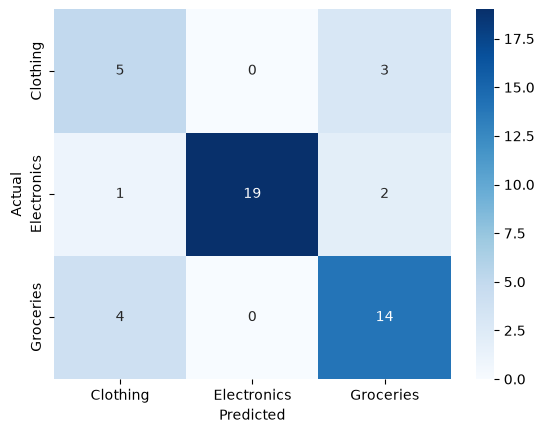

In [7]:
accuracy_score = metrics.accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy_score)

conf_mat = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
sn.heatmap(conf_mat, annot=True, fmt='d', cmap='Blues')